# Day 10 - Final model selection and business policy

This is the **final development/validation notebook before the one-time sealed test evaluation**. Compare the frozen RF/XGBoost candidates, quantify repeated-player uncertainty, perform one untuned demographic sensitivity, assess TRAIN-only calibration and freeze an explicit policy.

**TEST stays sealed.** No test predictor matrix, predictions, probability inspection or evaluation. Define the safe pre-test refit; do not execute it. No player-level prediction exports, commit or push.

Run with the project virtual environment from the repository root or `notebooks/`. Reusable implementation is in `src/business_policy.py` and `src/final_validation.py`.

In [1]:
from pathlib import Path
import sys
import matplotlib
matplotlib.use('Agg')
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/final_validation.py').is_file()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.final_validation import (
    load_inputs, compare_candidates, assess_calibration, export_outputs, decision_report,
)
from src.business_policy import ABLATION_TOLERANCES, verify_specification

def show_figure(name):
    display(Image(filename=str(ROOT / 'reports/figures' / name)))


## 1. Declare decision rules before viewing sensitivity results

A tiny fixed-budget difference will not outweigh an overall generalization advantage. Family choice considers discrimination, probability quality, train-validation gaps, all capacity scenarios, clustered uncertainty, interpretability and implementation.

Prefer demographic removal only if **every** loss remains within these practical tolerances: AUC/AP 0.005, Brier increase 0.002, lift decrease 0.05 and recall decrease 0.01 at both capacities. These are declared judgment limits, not financial or statistical significance thresholds.

Calibration selection requires Brier improvement >= 0.001, log-loss improvement >= 0.002 and ECE deterioration <= 0.002. Prefer sigmoid when essentially tied (Brier 0.0005, log loss 0.001) with the best eligible mapping. Otherwise keep raw scores. Calibration does not establish improved ranking.

In [2]:
display(pd.DataFrame([ABLATION_TOLERANCES], index=['Maximum tolerated predictive loss']))

,roc_auc,average_precision,brier_score,lift_at_top10pct,recall_at_top10pct,lift_at_top20pct,recall_at_top20pct
Maximum tolerated predictive loss,0.005,0.005,0.002,0.05,0.01,0.05,0.01


## 2. Reproduce saved model validation predictions

Load the Day 5 panel and saved Day 7/8 pipelines. Construct original TRAIN and VALIDATION only. The panel's safe pre-test rows are used only for eligibility aggregates. Models never receive test or embargo dates; prediction and fit guards reject mixed dates before estimator access. Known validation metrics must reproduce within 0.00005.

In [3]:
analysis = load_inputs(ROOT)
display(analysis['candidate_metrics'])
print('Saved RF/XGBoost validation metrics verified; TEST remains sealed.')

,model,roc_auc,average_precision,log_loss,brier_score,recall_at_top10pct,precision_at_top10pct,lift_at_top10pct,recall_at_top20pct,precision_at_top20pct,lift_at_top20pct
0,Random Forest,0.741491,0.559362,0.553515,0.191108,0.177232,0.625571,1.767460,0.344114,0.608696,1.719782
1,XGBoost,0.746382,0.563016,0.551458,0.190619,0.174644,0.616438,1.741658,0.337646,0.597254,1.687455


Saved RF/XGBoost validation metrics verified; TEST remains sealed.


## 3. Fixed-budget comparison and paired cluster bootstrap

Compare capacities 5/10/15/20/25/30%. Select ceil(n*f) player-snapshot observations, not deduplicated recipients. Score ties preserve original-panel input order, without label tie-breaking.

Use **1,000 paired UserID-cluster bootstrap replicates, seed 42**. Draw whole players with replacement, retain every row for each draw (including cluster multiplicity), recompute capacity/prevalence and score both models on identical draws. Row counts may vary. These conditional percentile intervals do not cover training/selection uncertainty or common calendar shocks.

The same function performs the single exact-configuration demographic ablation on original TRAIN, without tuning. The existing full-feature models remain unchanged.

In [4]:
analysis = compare_candidates(analysis, replicates=1000)
display(analysis['targeting'])
display(analysis['bootstrap'])

,target_fraction,selected_observations,actual_fraction,churn_observations_captured,precision,recall,lift,model
0,0.05,110,0.050366,72,0.654545,0.093144,1.849324,Random Forest
1,0.10,219,0.100275,137,0.625571,0.177232,1.767460,Random Forest
2,0.15,328,0.150183,196,0.597561,0.253558,1.688322,Random Forest
3,0.20,437,0.200092,266,0.608696,0.344114,1.719782,Random Forest
4,0.25,546,0.250000,324,0.593407,0.419146,1.676585,Random Forest
5,0.30,656,0.300366,374,0.570122,0.483829,1.610797,Random Forest
6,0.05,110,0.050366,73,0.663636,0.094437,1.875009,XGBoost
7,0.10,219,0.100275,135,0.616438,0.174644,1.741658,XGBoost
8,0.15,328,0.150183,203,0.618902,0.262613,1.748620,XGBoost
9,0.20,437,0.200092,261,0.597254,0.337646,1.687455,XGBoost


,metric,observed_difference,bootstrap_mean_difference,ci95_low,ci95_high,proportion_xgboost_better,proportion_tied,direction,valid_replicates,skipped_replicates,seed
0,roc_auc,0.004891,0.004941,-0.001733,0.011623,0.931,0.000,higher is better,1000,0,42
1,average_precision,0.003654,0.003173,-0.010038,0.017173,0.672,0.000,higher is better,1000,0,42
2,brier_score,-0.000489,-0.000477,-0.002528,0.001402,0.680,0.000,lower is better,1000,0,42
3,lift_at_top10pct,-0.025802,-0.010989,-0.131184,0.117779,0.381,0.094,higher is better,1000,0,42
4,recall_at_top10pct,-0.002587,-0.001101,-0.013149,0.011799,0.381,0.094,higher is better,1000,0,42
5,lift_at_top20pct,-0.032327,-0.026459,-0.101914,0.044702,0.217,0.050,higher is better,1000,0,42
6,recall_at_top20pct,-0.006468,-0.005297,-0.020411,0.008941,0.217,0.050,higher is better,1000,0,42


## 4. Demographic governance sensitivity

Remove Country, Language and Gender at both the input and transformed-feature levels. Compare seven metrics with full XGBoost, including signed and absolute differences. Prefer the simpler input set only if all declared tolerances are met. This is a predictive sensitivity analysis; protected-group outcome evidence is unavailable.

In [5]:
display(analysis['ablation'])
print('Demographics retained:', analysis['demographics_retained'])
print('Selected family:', analysis['selected_family'])

,metric,full_xgboost,demographic_free_xgboost,difference_free_minus_full,absolute_difference,predictive_loss,practical_loss_tolerance,within_tolerance
0,roc_auc,0.746382,0.744785,-0.001597,0.001597,0.001597,0.005,True
1,average_precision,0.563016,0.565764,0.002749,0.002749,-0.002749,0.005,True
2,brier_score,0.190619,0.190772,0.000154,0.000154,0.000154,0.002,True
3,lift_at_top10pct,1.741658,1.793262,0.051605,0.051605,-0.051605,0.050,True
4,recall_at_top10pct,0.174644,0.179819,0.005175,0.005175,-0.005175,0.010,True
5,lift_at_top20pct,1.687455,1.700386,0.012931,0.012931,-0.012931,0.050,True
6,recall_at_top20pct,0.337646,0.340233,0.002587,0.002587,-0.002587,0.010,True


Demographics retained: False
Selected family: XGBoost


## 5. Raw calibration and optional TRAIN-only mappings

Generate expanding temporal OOF scores for August-December 2005 using the exact selected estimator configuration and selected demographic policy. Each fitting label horizon ends **strictly before** the scoring snapshot's 30-day observation window begins; preprocess independently within each fit. This is stronger than a 60-day snapshot separation.

Pool only TRAIN OOF scores to fit sigmoid; permit isotonic only with >=1,000 observations, >=100 per class and >=100 distinct scores. Refit the base estimator on complete original TRAIN and evaluate mappings on VALIDATION. This is not the future pre-test refit.

ECE uses ten fixed equal-width probability bins: sum(n_bin/n * abs(mean score - observed rate)). Empty bins contribute zero; the final bin includes 1.0. Calibration intercept/slope on validation are descriptive logistic diagnostics only and are never applied as a mapping.

In [6]:
analysis = assess_calibration(analysis)
display(analysis['calibration_folds'])
display(pd.DataFrame([analysis['oof_summary']]))
display(analysis['calibration_comparison'])
print('Selected calibration:', analysis['calibration_choice'])

,fold,fit_start,fit_end,outcome_end,score_date,score_observation_start,gap_snapshot_days,fit_observations,score_observations
0,1,2005-03-31,2005-05-31,2005-07-30,2005-08-31,2005-08-02,92,4141,871
1,2,2005-03-31,2005-06-30,2005-08-29,2005-09-30,2005-09-01,92,5017,1043
2,3,2005-03-31,2005-07-31,2005-09-29,2005-10-31,2005-10-02,92,5836,902
3,4,2005-03-31,2005-08-31,2005-10-30,2005-11-30,2005-11-01,91,6707,873
4,5,2005-03-31,2005-09-30,2005-11-29,2005-12-31,2005-12-02,92,7750,855


,observations,unique_players,churn_rate,folds
0,4544,2108,0.34353,5


,method,brier_score,log_loss,ece,mean_probability,observed_prevalence,calibration_intercept,calibration_slope,roc_auc,average_precision
0,raw,0.190772,0.551661,0.026161,0.332823,0.353938,0.116174,1.006866,0.744785,0.565764
1,sigmoid,0.190406,0.551716,0.023286,0.344120,0.353938,0.112900,1.137662,0.744785,0.565764
2,isotonic,0.190823,0.551555,0.026950,0.344365,0.353938,0.095123,1.107498,0.743696,0.554552


Selected calibration: raw


## 6. Diagnostic thresholds and risk bands

Freeze **0.50** for the one-time test confusion matrix, as a diagnostic reference. Report validation F1 on the requested 0.20-0.80 grid in increments of 0.05; its maximum is only a grid-based diagnostic, not a profit optimum.

Risk bands partition ranked observations into bottom 50%, 50th-80th, 80th-90th and top 10%. Descending-rank cut points use ceil(n*.1), ceil(n*.2), ceil(n*.5), then n. Ties may span bands. Bands are presentation/prioritization tools, not clinical or regulatory categories.

In [7]:
display(analysis['thresholds'])
maximum_f1 = analysis['thresholds'].sort_values(['f1', 'threshold'], ascending=[False, True]).iloc[0]
print(f'Maximum-F1 grid reference: {maximum_f1.threshold:.2f}, F1={maximum_f1.f1:.4f}; diagnostic 0.50 remains frozen.')
display(analysis['risk_bands'])
display(analysis['final_targeting'])

,threshold,targeted_observations,targeting_percentage,precision,recall,f1,specificity,churn_rate_targeted,lift
0,0.20,1517,69.459707,0.466711,0.915912,0.618341,0.426648,0.466711,1.318624
1,0.25,1411,64.606227,0.481928,0.879690,0.622711,0.481928,0.481928,1.361617
2,0.30,1287,58.928571,0.492618,0.820181,0.615534,0.537208,0.492618,1.391822
3,0.35,1141,52.243590,0.510079,0.752911,0.608150,0.603827,0.510079,1.441154
4,0.40,971,44.459707,0.527291,0.662354,0.587156,0.674699,0.527291,1.489786
5,0.45,757,34.661172,0.546896,0.535576,0.541176,0.756910,0.546896,1.545175
6,0.50,514,23.534799,0.591440,0.393273,0.472416,0.851169,0.591440,1.671028
7,0.55,310,14.194139,0.619355,0.248383,0.354571,0.916371,0.619355,1.749898
8,0.60,133,6.089744,0.684211,0.117723,0.200883,0.970234,0.684211,1.933138
9,0.65,21,0.961538,0.571429,0.015524,0.030227,0.993622,0.571429,1.614489


Maximum-F1 grid reference: 0.25, F1=0.6227; diagnostic 0.50 remains frozen.


,band,observations,actual_fraction,average_predicted_risk,actual_churn_rate,lift
0,Very high risk (top 10%),219,0.100275,0.611586,0.634703,1.793262
1,High risk (80th-90th),218,0.099817,0.545326,0.568807,1.607083
2,Medium risk (50th-80th),655,0.299908,0.445768,0.464122,1.311310
3,Low risk (bottom 50%),1092,0.500000,0.166747,0.188645,0.532988


,target_fraction,selected_observations,actual_fraction,churn_observations_captured,precision,recall,lift,model
0,0.05,110,0.050366,75,0.681818,0.097025,1.926379,Final selected XGBoost
1,0.10,219,0.100275,139,0.634703,0.179819,1.793262,Final selected XGBoost
2,0.15,328,0.150183,201,0.612805,0.260026,1.731392,Final selected XGBoost
3,0.20,437,0.200092,263,0.601831,0.340233,1.700386,Final selected XGBoost
4,0.25,546,0.250000,320,0.586081,0.413972,1.655886,Final selected XGBoost
5,0.30,656,0.300366,373,0.568598,0.482536,1.606490,Final selected XGBoost


## 7. Exact safe pre-test refit boundary - define only

The first test snapshot is 2006-08-31. Its inclusive 30-day observation starts S-29 days. A pre-test fitting snapshot must satisfy S+60 days < first test observation start. Determine this exactly rather than assuming month labels are safe. Previously embargoed January/February may become usable after development is frozen; June/July remain unsafe.

The functions return aggregate counts and boundary diagnostics, never a frame for fitting or scoring. This notebook **does not execute the final pre-test refit**.

In [8]:
display(pd.DataFrame([analysis['refit_summary']]))
display(analysis['refit_boundary'])
display(analysis['refit_snapshots'])

,first_test_snapshot,first_test_observation_start,latest_safe_calendar_snapshot,refit_start,refit_end,observations,unique_players,churn_rate
0,2006-08-31,2006-08-02,2006-06-02,2005-03-31,2006-05-31,14242,3651,0.359009


,snapshot_date,outcome_end,safe_for_future_refit
0,2006-01-31,2006-04-01,True
1,2006-02-28,2006-04-29,True
2,2006-05-31,2006-07-30,True
3,2006-06-30,2006-08-29,False
4,2006-07-31,2006-09-29,False


,snapshot_date,observations,unique_players,churn_rate,outcome_end
0,2005-03-31,1805,1805,0.401662,2005-05-30
1,2005-04-30,1314,1314,0.392694,2005-06-29
2,2005-05-31,1022,1022,0.367906,2005-07-30
3,2005-06-30,876,876,0.341324,2005-08-29
4,2005-07-31,819,819,0.328449,2005-09-29
5,2005-08-31,871,871,0.300804,2005-10-30
6,2005-09-30,1043,1043,0.348993,2005-11-29
7,2005-10-31,902,902,0.363636,2005-12-30
8,2005-11-30,873,873,0.364261,2006-01-29
9,2005-12-31,855,855,0.338012,2006-03-01


## 8. Export aggregate evidence and freeze the specification

Write the decision report, exact Markdown/JSON specification, capacity and bootstrap comparisons, demographic ablation, calibration tables/folds, threshold/risk-band tables and refit eligibility summaries. Create five concise figures with matplotlib.

Persist the original-TRAIN final development model and selected calibration policy locally under ignored `models/` paths. Preserve both original RF/XGBoost artifacts. No player-level probability/label records or OOF rows are exported.

In [9]:
export_outputs(analysis)
verify_specification(analysis['specification'], analysis['selected_model'])
report = decision_report(analysis)
def show_section(title):
    text = report.split('## ' + title + '\n', 1)[1].split('\n## ', 1)[0]
    display(Markdown(text))
print('Specification frozen and checked against estimator and fitted preprocessing.')
print('Reports and five figures exported. TEST remains sealed.')

Specification frozen and checked against estimator and fitted preprocessing.
Reports and five figures exported. TEST remains sealed.


## 9. Final family and feature-variant decision

In [10]:
show_section('Decision and scope')
show_section('Validation reproduction and generalization')
show_section('One demographic sensitivity analysis')


**Final model family: XGBoost.** Its stronger overall validation discrimination and probability quality, much smaller train-validation gaps, and established SHAP explanations outweigh Random Forest's small observed top-budget advantage. No financial utility function or universal contact capacity is assumed. This is the final development/validation decision before one sealed test evaluation.

Variant: **demographics removed**. Probability policy: **raw**. The exact specification and all estimator parameters are frozen in `final_model_specification.md` and `final_model_specification.json`. Logistic Regression remains the historical baseline.



Original TRAIN: 2005-03-31 through 2005-12-31 (10,380 observations). Validation: 2006-03-31 through 2006-05-31 (2,184 observations, 1,310 players). All saved candidate metrics reproduce within 0.00005. No test predictor matrix or predictions were created.

| model | roc_auc | average_precision | log_loss | brier_score | recall_at_top10pct | precision_at_top10pct | lift_at_top10pct | recall_at_top20pct | precision_at_top20pct | lift_at_top20pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Random Forest | 0.7415 | 0.5594 | 0.5535 | 0.1911 | 0.1772 | 0.6256 | 1.7675 | 0.3441 | 0.6087 | 1.7198 |
| XGBoost | 0.7464 | 0.5630 | 0.5515 | 0.1906 | 0.1746 | 0.6164 | 1.7417 | 0.3376 | 0.5973 | 1.6875 |

Historical train-minus-validation ROC-AUC gaps: RF 0.0763, XGBoost 0.0398; average-precision gaps: RF 0.1265, XGBoost 0.0675. These favor XGBoost's generalization behavior, but are descriptive and do not establish future performance. Logistic baseline: ROC-AUC 0.7295, AP 0.5342, Brier 0.1963. XGBoost adds a dependency versus sklearn RF, but both use the same practical train-fitted preprocessing and are already implemented and explainable.

Raw final selected variant train/validation metrics (before any probability mapping):

| metric | train | validation | train_minus_validation |
| --- | --- | --- | --- |
| roc_auc | 0.7838 | 0.7448 | 0.0390 |
| average_precision | 0.6243 | 0.5658 | 0.0585 |
| brier_score | 0.1796 | 0.1908 | -0.0112 |



Retrained the exact selected XGBoost settings once on original TRAIN with Country, Language and Gender removed. No tuning or alternative feature search. Before running, practical-loss tolerances were fixed at ROC-AUC/AP 0.005, Brier increase 0.002, lift decrease 0.05 and recall decrease 0.01 at both 10% and 20%. These are declared project judgment limits, not profit, fairness or statistical thresholds. Removal is preferred only if every metric meets its tolerance.

| metric | full_xgboost | demographic_free_xgboost | difference_free_minus_full | absolute_difference | predictive_loss | practical_loss_tolerance | within_tolerance |
| --- | --- | --- | --- | --- | --- | --- | --- |
| roc_auc | 0.7464 | 0.7448 | -0.0016 | 0.0016 | 0.0016 | 0.0050 | True |
| average_precision | 0.5630 | 0.5658 | 0.0027 | 0.0027 | -0.0027 | 0.0050 | True |
| brier_score | 0.1906 | 0.1908 | 0.0002 | 0.0002 | 0.0002 | 0.0020 | True |
| lift_at_top10pct | 1.7417 | 1.7933 | 0.0516 | 0.0516 | -0.0516 | 0.0500 | True |
| recall_at_top10pct | 0.1746 | 0.1798 | 0.0052 | 0.0052 | -0.0052 | 0.0100 | True |
| lift_at_top20pct | 1.6875 | 1.7004 | 0.0129 | 0.0129 | -0.0129 | 0.0500 | True |
| recall_at_top20pct | 0.3376 | 0.3402 | 0.0026 | 0.0026 | -0.0026 | 0.0100 | True |

All losses fall within the declared tolerances; freeze the demographic-free variant for simpler inputs and reduced direct demographic dependence.

This sensitivity does not establish group fairness, remove behavioral proxies, or quantify protected-group outcomes. Demographic exclusion is not proof of fairness. Prior Day 9 SHAP findings explain the full model; they are not automatically exact attributions for a changed feature set. The paired bootstrap above compares the original full-feature candidates; it does not quantify uncertainty for the demographic ablation or prove the final variant superior to RF.


## 10. Business comparison with uncertainty

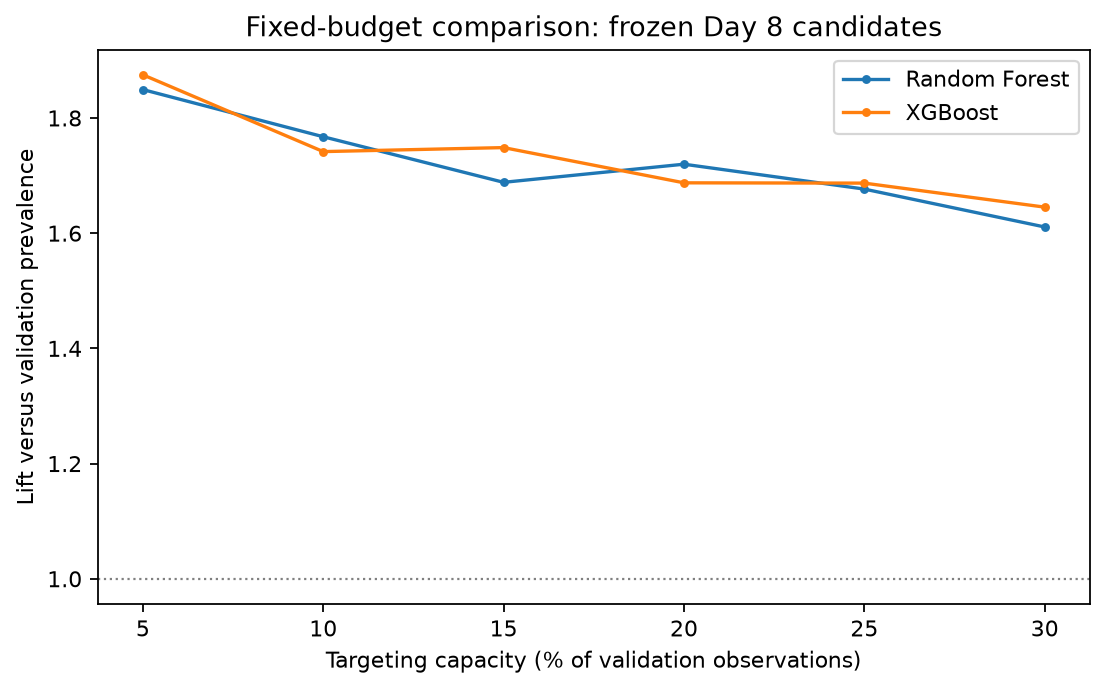

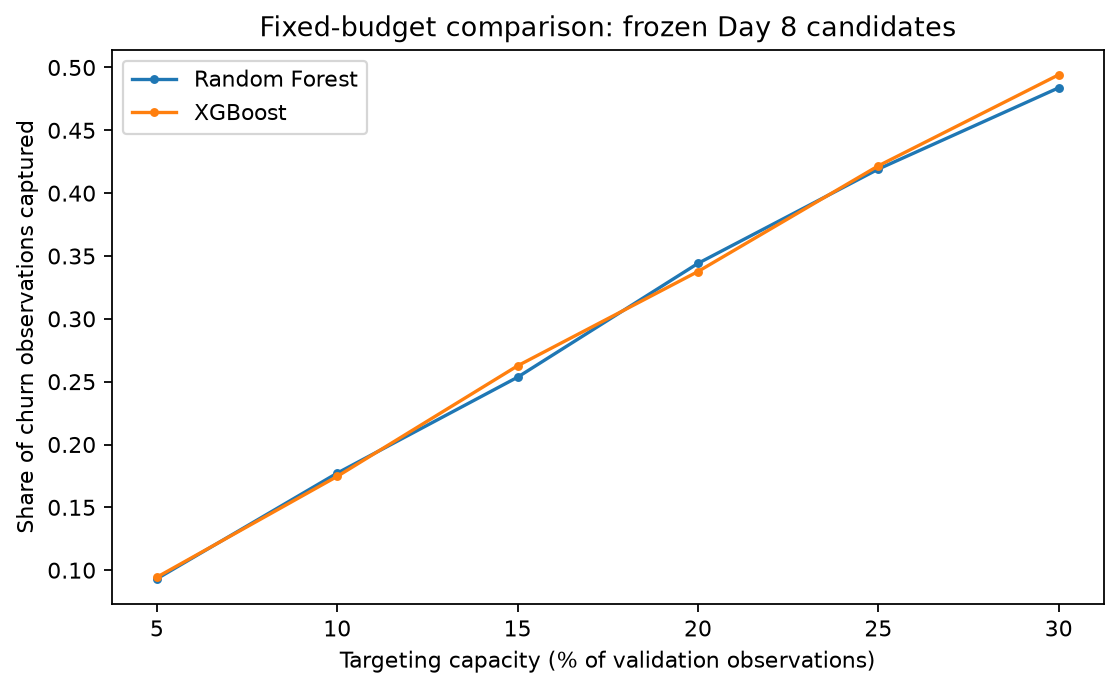


| metric | observed_difference | bootstrap_mean_difference | ci95_low | ci95_high | proportion_xgboost_better | proportion_tied | direction | valid_replicates | skipped_replicates | seed |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| roc_auc | 0.0049 | 0.0049 | -0.0017 | 0.0116 | 0.9310 | 0.0000 | higher is better | 1000 | 0 | 42 |
| average_precision | 0.0037 | 0.0032 | -0.0100 | 0.0172 | 0.6720 | 0.0000 | higher is better | 1000 | 0 | 42 |
| brier_score | -0.0005 | -0.0005 | -0.0025 | 0.0014 | 0.6800 | 0.0000 | lower is better | 1000 | 0 | 42 |
| lift_at_top10pct | -0.0258 | -0.0110 | -0.1312 | 0.1178 | 0.3810 | 0.0940 | higher is better | 1000 | 0 | 42 |
| recall_at_top10pct | -0.0026 | -0.0011 | -0.0131 | 0.0118 | 0.3810 | 0.0940 | higher is better | 1000 | 0 | 42 |
| lift_at_top20pct | -0.0323 | -0.0265 | -0.1019 | 0.0447 | 0.2170 | 0.0500 | higher is better | 1000 | 0 | 42 |
| recall_at_top20pct | -0.0065 | -0.0053 | -0.0204 | 0.0089 | 0.2170 | 0.0500 | higher is better | 1000 | 0 | 42 |

Each replicate draws the same number of distinct-player clusters with replacement, retains every validation snapshot for each sampled player (including repeated copies when a player is drawn twice), and evaluates both models on identical draws. Rank capacities and prevalence are recomputed in each replicate. Total row counts can vary. Intervals are 2.5th/97.5th percentiles of XGBoost-minus-RF differences; Brier favors negative differences. The proportion better is a descriptive bootstrap frequency, not a posterior probability, p-value, or proof of superiority. Intervals condition on the fitted models and selected validation period; they do not include model-selection or training uncertainty.

- lift_at_top10pct: XGB minus RF -0.02580, 95% CI [-0.13118, +0.11778]; contains zero: the observed RF advantage is not clearly separated from validation uncertainty.
- recall_at_top10pct: XGB minus RF -0.00259, 95% CI [-0.01315, +0.01180]; contains zero: the observed RF advantage is not clearly separated from validation uncertainty.
- lift_at_top20pct: XGB minus RF -0.03233, 95% CI [-0.10191, +0.04470]; contains zero: the observed RF advantage is not clearly separated from validation uncertainty.
- recall_at_top20pct: XGB minus RF -0.00647, 95% CI [-0.02041, +0.00894]; contains zero: the observed RF advantage is not clearly separated from validation uncertainty.


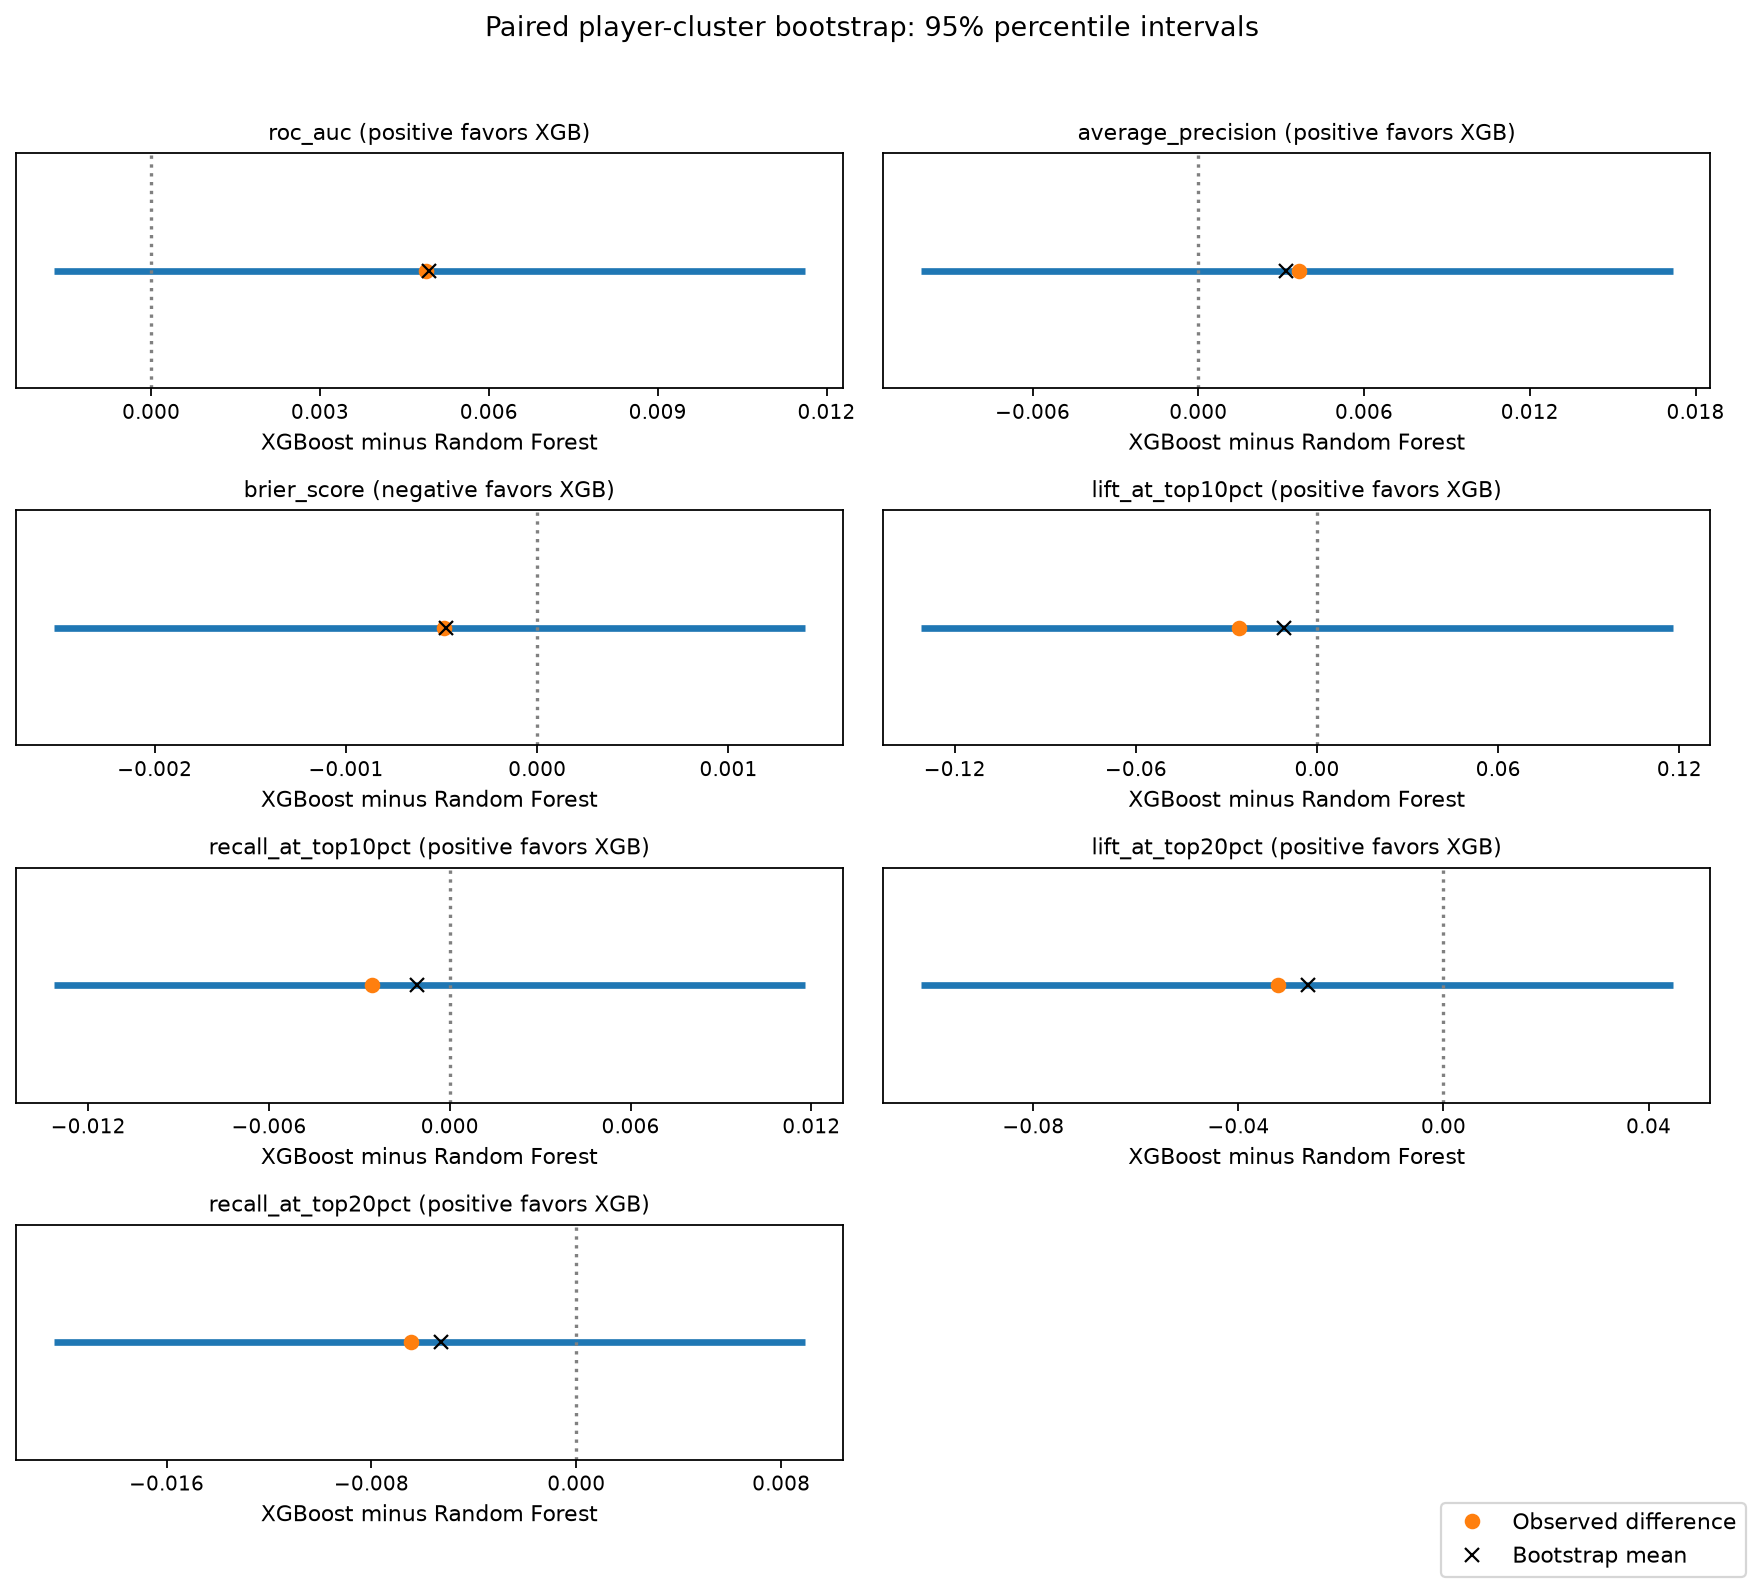

In [11]:
show_figure('policy_lift_by_capacity.png')
show_figure('policy_recall_by_capacity.png')
show_section('Paired cluster-bootstrap uncertainty')
show_figure('policy_bootstrap_intervals.png')

## 11. Calibration decision


Leading variant raw Brier 0.190772, log loss 0.551661, mean probability 33.2823%, observed prevalence 35.3938%, ECE 0.026161. Descriptive validation logistic calibration intercept +0.1162, slope 1.0069; ideal values are 0 and 1. This regression is an assessment only: it is never applied as a calibration mapping.

ECE uses ten fixed equal-width probability bins [0,.1), ... [.9,1]; ECE = sum(n_bin/n * abs(mean probability - observed frequency)). Empty bins contribute zero. Logistic calibration diagnostics fit outcome on clipped logit(probability), clipping to [1e-6,1-1e-6] for finite logits. Calibration curves can be noisy in sparse high-score bins.

The calibration experiment uses five expanding temporal folds within TRAIN. Every fitting snapshot's 60-day label horizon ends strictly before the scoring snapshot's 30-day observation window starts, stronger than a 60-day snapshot gap. Preprocessing is independently fitted within each fitting fold. Repeated players across time remain permitted by the original known-player design.

| fold | fit_start | fit_end | outcome_end | score_date | score_observation_start | gap_snapshot_days | fit_observations | score_observations |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 2005-03-31 00:00:00 | 2005-05-31 00:00:00 | 2005-07-30 00:00:00 | 2005-08-31 00:00:00 | 2005-08-02 00:00:00 | 92 | 4141 | 871 |
| 2 | 2005-03-31 00:00:00 | 2005-06-30 00:00:00 | 2005-08-29 00:00:00 | 2005-09-30 00:00:00 | 2005-09-01 00:00:00 | 92 | 5017 | 1043 |
| 3 | 2005-03-31 00:00:00 | 2005-07-31 00:00:00 | 2005-09-29 00:00:00 | 2005-10-31 00:00:00 | 2005-10-02 00:00:00 | 92 | 5836 | 902 |
| 4 | 2005-03-31 00:00:00 | 2005-08-31 00:00:00 | 2005-10-30 00:00:00 | 2005-11-30 00:00:00 | 2005-11-01 00:00:00 | 91 | 6707 | 873 |
| 5 | 2005-03-31 00:00:00 | 2005-09-30 00:00:00 | 2005-11-29 00:00:00 | 2005-12-31 00:00:00 | 2005-12-02 00:00:00 | 92 | 7750 | 855 |

Pooled OOF support: 4,544 rows, 2,108 players, 34.35% inactivity. Sigmoid fits a nonnegative-slope two-parameter logistic map of OOF logits. Isotonic is allowed only with at least 1,000 OOF observations, 100 per class and 100 distinct scores. Both mappings are fitted exclusively on pooled TRAIN-OOF labels and predictions. The exact frozen base estimator is then refitted to complete original TRAIN before validation scoring. This is not the future pre-test refit.

| method | brier_score | log_loss | ece | mean_probability | observed_prevalence | calibration_intercept | calibration_slope | roc_auc | average_precision |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| raw | 0.1908 | 0.5517 | 0.0262 | 0.3328 | 0.3539 | 0.1162 | 1.0069 | 0.7448 | 0.5658 |
| sigmoid | 0.1904 | 0.5517 | 0.0233 | 0.3441 | 0.3539 | 0.1129 | 1.1377 | 0.7448 | 0.5658 |
| isotonic | 0.1908 | 0.5516 | 0.0269 | 0.3444 | 0.3539 | 0.0951 | 1.1075 | 0.7437 | 0.5546 |

Prespecified selection rule: retain raw unless a mapping improves Brier by at least 0.001 and log loss by at least 0.002, with ECE worsening no more than 0.002. Prefer sigmoid if within Brier 0.0005 and log loss 0.001 of the best eligible method. These are practical tolerances, not significance tests. Isotonic can introduce ties and endpoint scores; ranking changes are not evidence of improved discrimination. Earlier TRAIN-OOF and later validation distributions can differ, and selecting a mapping using validation adds selection optimism.

**Selected calibration: raw.** The mappings do not provide sufficiently consistent material gains under the declared rule, so retain raw scores.


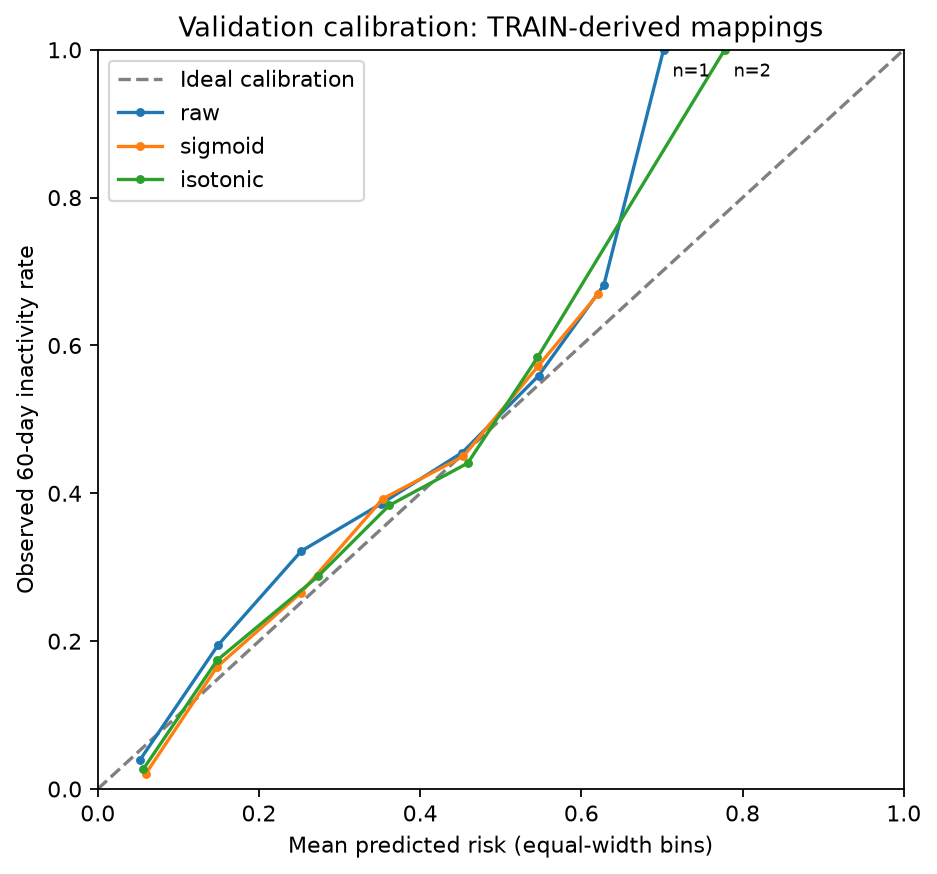

In [12]:
show_section('Calibration assessment and TRAIN-only experiment')
show_figure('policy_calibration_comparison.png')

## 12. Business-policy interpretation


Primary output is the final model's probability/risk score for extended inactivity. Use ranking to prioritize within a real capacity: top 10% and top 20% are standard reporting scenarios; 5/15/25/30% remain alternatives. No contact costs, customer lifetime value, treatment effect, incremental retention or ROI are known. No probability threshold is claimed to maximize profit. Campaign design must separately handle repeated-player contacts, eligibility and governance.

Freeze **0.50** as the diagnostic confusion-matrix threshold for the next notebook. It is not a deployment or financial optimum.

| threshold | targeted_observations | targeting_percentage | precision | recall | f1 | specificity | churn_rate_targeted | lift |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.2000 | 1517 | 69.4597 | 0.4667 | 0.9159 | 0.6183 | 0.4266 | 0.4667 | 1.3186 |
| 0.2500 | 1411 | 64.6062 | 0.4819 | 0.8797 | 0.6227 | 0.4819 | 0.4819 | 1.3616 |
| 0.3000 | 1287 | 58.9286 | 0.4926 | 0.8202 | 0.6155 | 0.5372 | 0.4926 | 1.3918 |
| 0.3500 | 1141 | 52.2436 | 0.5101 | 0.7529 | 0.6082 | 0.6038 | 0.5101 | 1.4412 |
| 0.4000 | 971 | 44.4597 | 0.5273 | 0.6624 | 0.5872 | 0.6747 | 0.5273 | 1.4898 |
| 0.4500 | 757 | 34.6612 | 0.5469 | 0.5356 | 0.5412 | 0.7569 | 0.5469 | 1.5452 |
| 0.5000 | 514 | 23.5348 | 0.5914 | 0.3933 | 0.4724 | 0.8512 | 0.5914 | 1.6710 |
| 0.5500 | 310 | 14.1941 | 0.6194 | 0.2484 | 0.3546 | 0.9164 | 0.6194 | 1.7499 |
| 0.6000 | 133 | 6.0897 | 0.6842 | 0.1177 | 0.2009 | 0.9702 | 0.6842 | 1.9331 |
| 0.6500 | 21 | 0.9615 | 0.5714 | 0.0155 | 0.0302 | 0.9936 | 0.5714 | 1.6145 |
| 0.7000 | 1 | 0.0458 | 1.0000 | 0.0013 | 0.0026 | 1.0000 | 1.0000 | 2.8254 |
| 0.7500 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | nan |
| 0.8000 | 0 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | nan |

The maximum-F1 threshold on this **prespecified grid** is 0.25 (F1 0.6227); this is a validation diagnostic reference only, not a replacement for the frozen 0.50 diagnostic or an exhaustive optimum over all possible scores.



| band | observations | actual_fraction | average_predicted_risk | actual_churn_rate | lift |
| --- | --- | --- | --- | --- | --- |
| Very high risk (top 10%) | 219 | 0.1003 | 0.6116 | 0.6347 | 1.7933 |
| High risk (80th-90th) | 218 | 0.0998 | 0.5453 | 0.5688 | 1.6071 |
| Medium risk (50th-80th) | 655 | 0.2999 | 0.4458 | 0.4641 | 1.3113 |
| Low risk (bottom 50%) | 1092 | 0.5000 | 0.1667 | 0.1886 | 0.5330 |

Four bands partition the ranked population: bottom 50%, 50th-80th, 80th-90th and top 10%. Starting from descending score order, boundaries use ceil(n*.1), ceil(n*.2), ceil(n*.5), then n. Ties use stable original-panel order and can split identical scores across bands. Bands are relative to the scoring cohort, not fixed probability cutoffs; mean scores and observed rates need not be perfectly monotonic. They are presentation/prioritization tools, not clinical or regulatory categories. Recompute ranks within each future eligible campaign cohort without labels; deduplication requires a separate operational policy.

Final selected variant/policy capacity results (the RF/XGB comparison above uses the original full-feature candidates):

| target_fraction | selected_observations | actual_fraction | churn_observations_captured | precision | recall | lift | model |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 0.0500 | 110 | 0.0504 | 75 | 0.6818 | 0.0970 | 1.9264 | Final selected XGBoost |
| 0.1000 | 219 | 0.1003 | 139 | 0.6347 | 0.1798 | 1.7933 | Final selected XGBoost |
| 0.1500 | 328 | 0.1502 | 201 | 0.6128 | 0.2600 | 1.7314 | Final selected XGBoost |
| 0.2000 | 437 | 0.2001 | 263 | 0.6018 | 0.3402 | 1.7004 | Final selected XGBoost |
| 0.2500 | 546 | 0.2500 | 320 | 0.5861 | 0.4140 | 1.6559 | Final selected XGBoost |
| 0.3000 | 656 | 0.3004 | 373 | 0.5686 | 0.4825 | 1.6065 | Final selected XGBoost |


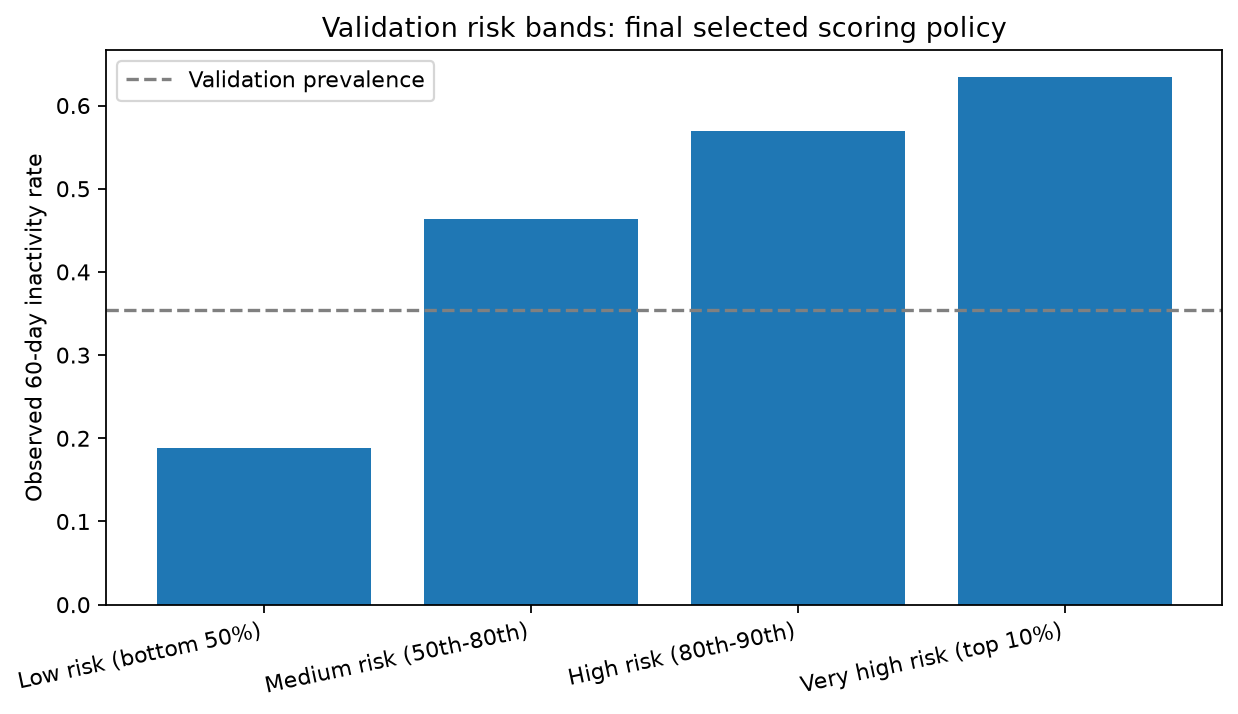

In [13]:
show_section('Business policy and diagnostic thresholds')
show_section('Risk bands')
show_figure('policy_risk_band_churn.png')

## 13. Next notebook: frozen refit and one-time test evaluation

In [14]:
show_section('Exact pre-test refit protocol: defined, not executed')
show_section('One-time held-out evaluation plan')


First test snapshot: 2006-08-31; inclusive 30-day observation starts 2006-08-02. Require S + 60 days < 2006-08-02, so the latest admissible calendar snapshot is **2006-06-02**. For month-end snapshots the last safe one is **2006-05-31** (outcome ends 2006-07-30).

| snapshot_date | outcome_end | safe_for_future_refit |
| --- | --- | --- |
| 2006-01-31 00:00:00 | 2006-04-01 00:00:00 | True |
| 2006-02-28 00:00:00 | 2006-04-29 00:00:00 | True |
| 2006-05-31 00:00:00 | 2006-07-30 00:00:00 | True |
| 2006-06-30 00:00:00 | 2006-08-29 00:00:00 | False |
| 2006-07-31 00:00:00 | 2006-09-29 00:00:00 | False |

January and February 2006 may join the future refit because their original embargo role separated development train/validation; their outcomes are available before the first test observation period. June and July remain excluded. No unsafe rows are used for the aggregate counts below.

| snapshot_date | observations | unique_players | churn_rate | outcome_end |
| --- | --- | --- | --- | --- |
| 2005-03-31 00:00:00 | 1805 | 1805 | 0.4017 | 2005-05-30 00:00:00 |
| 2005-04-30 00:00:00 | 1314 | 1314 | 0.3927 | 2005-06-29 00:00:00 |
| 2005-05-31 00:00:00 | 1022 | 1022 | 0.3679 | 2005-07-30 00:00:00 |
| 2005-06-30 00:00:00 | 876 | 876 | 0.3413 | 2005-08-29 00:00:00 |
| 2005-07-31 00:00:00 | 819 | 819 | 0.3284 | 2005-09-29 00:00:00 |
| 2005-08-31 00:00:00 | 871 | 871 | 0.3008 | 2005-10-30 00:00:00 |
| 2005-09-30 00:00:00 | 1043 | 1043 | 0.3490 | 2005-11-29 00:00:00 |
| 2005-10-31 00:00:00 | 902 | 902 | 0.3636 | 2005-12-30 00:00:00 |
| 2005-11-30 00:00:00 | 873 | 873 | 0.3643 | 2006-01-29 00:00:00 |
| 2005-12-31 00:00:00 | 855 | 855 | 0.3380 | 2006-03-01 00:00:00 |
| 2006-01-31 00:00:00 | 862 | 862 | 0.3561 | 2006-04-01 00:00:00 |
| 2006-02-28 00:00:00 | 816 | 816 | 0.3517 | 2006-04-29 00:00:00 |
| 2006-03-31 00:00:00 | 803 | 803 | 0.3836 | 2006-05-30 00:00:00 |
| 2006-04-30 00:00:00 | 736 | 736 | 0.3315 | 2006-06-29 00:00:00 |
| 2006-05-31 00:00:00 | 645 | 645 | 0.3426 | 2006-07-30 00:00:00 |

Planned final refit: **2005-03-31 through 2006-05-31**, **14,242 observations**, **3,651 players**, **35.9009%** inactivity. This notebook reports eligibility only and does not perform this pre-test refit.

Next notebook: verify the frozen specification and data hash, select only eligible snapshots by the strict date rule, fit the frozen preprocessing and estimator on that pre-test data, and retain the already frozen TRAIN-OOF calibration mapping if selected (otherwise no mapping). Missing indicators and category levels may be relearned by the same preprocessing algorithm on safe pre-test data; raw predictor definitions/hyperparameters remain fixed. Freeze the resulting fitted artifact before making test predictions.



Score only 2006-08-31 through 2006-11-30 once after the freeze/refit. Compute ROC-AUC; PR-AUC as average precision; Brier; log loss; precision, recall, F1 and specificity at diagnostic 0.50; lift/recall at top 10% and top 20%. Use 1,000 seeded (42) whole-UserID cluster bootstrap replicates for 95% percentile intervals. Ranking ties use stable original-panel order. Produce the calibration plot (same ten bins), ROC curve, PR curve, cumulative gains/lift and confusion matrix. Freeze risk bands/capacity definitions; do not choose a new threshold, calibrator, feature set or family after inspecting test outcomes. If results disappoint, report them; any later development requires genuinely new holdout data. No post-test tuning is allowed.


## 14. Verification and limitations

Tests cover sealed-date rejection before predict/predict_proba/fit, whole-cluster sampling, capacity arithmetic, actual demographic exclusion, TRAIN-OOF calibration provenance, frozen parameters/features/preprocessing and the exact nonoverlapping refit boundary.

Run from the repository root:

```powershell
.\venv\Scripts\python.exe -m unittest discover -s tests -v
```

Do not tune any decision after test evaluation.

In [15]:
import json
import hashlib
import joblib
metadata = json.loads((ROOT / 'reports/final_validation_run_metadata.json').read_text())
spec = json.loads((ROOT / 'reports/final_model_specification.json').read_text())
verify_specification(spec, joblib.load(ROOT / 'models/final_development_model.joblib'))
for field in ['test_predictions_generated', 'test_probabilities_inspected', 'test_evaluated',
              'pretest_refit_executed', 'player_level_predictions_exported']:
    assert metadata[field] is False
for name, before in metadata['original_model_hashes'].items():
    assert hashlib.sha256((ROOT / 'models' / name).read_bytes()).hexdigest() == before
assert metadata['bootstrap_replicates'] == 1000
show_section('Limitations and status')
print('All artifact checks passed. No test scoring or pre-test refit occurred.')


- Validation has been reused across model-family, feature-variant and calibration choices, creating selection optimism; bootstrap intervals do not correct it.
- Repeated-player clustering respects dependence within a player but not shared calendar shocks; only three validation months are available.
- Historical 2005-2006 data, cohort drift, correlated features and unverified demographic history limit generalization; no causal retention benefit or ROI is established.
- Scores concern extended inactivity, not permanent departure, gambling harm, problem gambling, customer value or causal behavioral explanations.
- Protected-group outcome analysis is unavailable; neither ablation nor SHAP is a fairness audit.
- Calibration trained on earlier OOF periods may not transfer to a final pre-test refit or future populations.
- TEST remains completely sealed. No pre-test final refit, test transformation, test predictions, probability inspection, or test evaluation occurred. No player-level predictions were exported; original artifacts were preserved. No commit or push was performed.

All model-development decisions were frozen before evaluating the held-out test period.


All artifact checks passed. No test scoring or pre-test refit occurred.
